# 03. Univariate Linear Regression from Scratch
### Gradient Descent for a Single Feature (Qatar Rental Market)

In this notebook, we combine the **Cost Function** from Notebook 01 and the **Gradient Descent** optimization rule from Notebook 02 to train a full Linear Regression model from scratch.

---

### The Model
$$f_{w,b}(x) = w x + b$$

where:
- $x$ is the apartment area in square meters ($m^2$).
- $\hat{y} = f_{w,b}(x)$ is the predicted monthly rent in Qatari Riyals (QAR).
- $w$ is the slope parameter (QAR per $m^2$).
- $b$ is the intercept parameter (base rent in QAR).

---

### Dataset: Doha & Lusail Rental Listings
We will use `data/qatar_living_rent.csv` to train our model.

In [9]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

## Section 1: Loading the Dataset

Let's load the Qatar rental data and inspect feature vectors.

In [10]:
# Step 2: Load data from data/ subfolder
df = pd.read_csv('data/qatar_living_rent.csv')

x = df['area_m2'].values.astype(float)
y = df['monthly_rent_qar'].values.astype(float)
m = len(y)

print(f"Loaded {m} apartment records.")
print(f"Area range : {x.min():.0f} m² to {x.max():.0f} m²")
print(f"Rent range : {y.min():,.0f} QAR to {y.max():,.0f} QAR")

Loaded 16 apartment records.
Area range : 45 m² to 240 m²
Rent range : 3,800 QAR to 14,800 QAR


## Section 2: Mathematical Derivation of Gradients

Recall the Mean Squared Error cost (divided by $m$):
$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (w x^{(i)} + b - y^{(i)})^2$$

To update $w$ and $b$ using gradient descent, we compute the partial derivatives:

### Derivative with respect to $w$:
Applying the chain rule: $\frac{d}{du}(u^2) = 2u$:

$$\frac{\partial J}{\partial w} = \frac{2}{m} \sum_{i=1}^{m} (w x^{(i)} + b - y^{(i)}) x^{(i)} = \frac{2}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) x^{(i)}$$

### Derivative with respect to $b$:
$$\frac{\partial J}{\partial b} = \frac{2}{m} \sum_{i=1}^{m} (w x^{(i)} + b - y^{(i)}) = \frac{2}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$

### Simultaneous Update Rule:
At each iteration, update **both** parameters simultaneously:
$$w \leftarrow w - \alpha \frac{\partial J}{\partial w}$$
$$b \leftarrow b - \alpha \frac{\partial J}{\partial b}$$

In [11]:
# Step 3: Implement cost and gradient functions

def compute_cost(x, y, w, b):
    """Compute MSE cost J(w, b) = (1/m) * sum((w*x + b - y)^2)."""
    m = len(y)
    y_hat = w * x + b
    errors = y_hat - y
    return (1 / m) * np.sum(errors ** 2)

def compute_gradient(x, y, w, b):
    """
    Compute partial derivatives dj/dw and dj/db.
    
    Returns:
        dj_dw (float): Gradient w.r.t slope w  = (2/m) * sum(error * x)
        dj_db (float): Gradient w.r.t bias b   = (2/m) * sum(error)
    """
    m = len(y)
    y_hat = w * x + b
    errors = y_hat - y
    
    # dj/dw = (2/m) * sum(error * x)
    dj_dw = (2 / m) * np.sum(errors * x)
    # dj_db = (2/m) * sum(error)
    dj_db = (2 / m) * np.sum(errors)
    
    return dj_dw, dj_db

## Section 3: Implementing the Gradient Descent Training Loop

Let's write a clean, straightforward training function that iterates for a set number of epochs and records the cost history.

In [12]:
# Step 4: Gradient descent training function
def gradient_descent(x, y, w_init, b_init, alpha, num_iters):
    """
    Batch gradient descent for univariate linear regression.
    
    Returns:
        w, b: Optimized model parameters
        cost_history: List of cost values at each iteration
        param_history: List of (w, b) tuples at periodic intervals
    """
    w = w_init
    b = b_init
    cost_history = []
    param_history = [(w, b)]
    
    for i in range(num_iters):
        # Calculate gradients
        dj_dw, dj_db = compute_gradient(x, y, w, b)
        
        # Update parameters simultaneously
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        
        # Record cost
        cost = compute_cost(x, y, w, b)
        cost_history.append(cost)
        
        # Save parameter snapshots for visualization
        if i % 100 == 0 or i == num_iters - 1:
            param_history.append((w, b))
            
    return w, b, cost_history, param_history

## Section 4: Training on Qatar Apartment Rent

We initialize $w = 0$ and $b = 0$.
Because area ($x$) is around $50$ to $250$, its square in the gradient formula is large. A learning rate of $\alpha = 0.00003$ ensures smooth, stable convergence.

In [13]:
# Step 5: Run gradient descent
w_init = 0.0
b_init = 0.0
alpha = 0.00003
iterations = 1500

w_final, b_final, cost_history, param_history = gradient_descent(
    x, y, w_init, b_init, alpha, iterations
)

print(f"Training completed across {iterations} iterations.")
print(f"Optimal slope     (w): {w_final:.2f} QAR per m²")
print(f"Optimal intercept (b): {b_final:.2f} QAR")
print(f"Initial MSE Cost: {cost_history[0]:,.1f}")
print(f"Final MSE Cost  : {cost_history[-1]:,.1f}")

Training completed across 1500 iterations.
Optimal slope     (w): 64.50 QAR per m²
Optimal intercept (b): 21.40 QAR
Initial MSE Cost: 6,746,184.1
Final MSE Cost  : 326,600.5


## Section 5: Visualizing Training Convergence

Let's inspect two critical diagnostic plots:
1. **The Learning Curve:** Cost $J$ vs. Epoch Number (confirming error decreases monotonically).
2. **The Fitted Regression Line:** Overlaid against the actual Qatar rental data points.

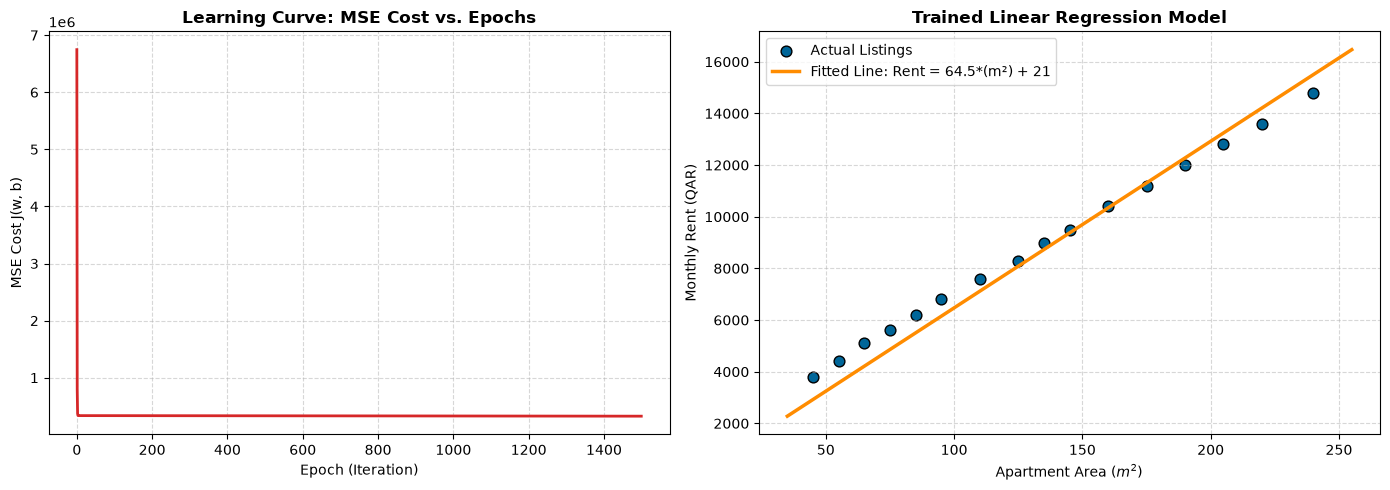

In [14]:
# Step 6: Plot learning curve and final regression line
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Learning curve
ax1.plot(range(len(cost_history)), cost_history, color='#d62728', linewidth=2)
ax1.set_title('Learning Curve: MSE Cost vs. Epochs', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch (Iteration)')
ax1.set_ylabel('MSE Cost J(w, b)')
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Fitted line on Qatar rent data
x_plot = np.linspace(35, 255, 100)
y_plot = w_final * x_plot + b_final

ax2.scatter(x, y, color='#006699', s=60, edgecolors='k', label='Actual Listings')
ax2.plot(x_plot, y_plot, color='darkorange', linewidth=2.5, 
         label=f'Fitted Line: Rent = {w_final:.1f}*(m²) + {b_final:.0f}')
ax2.set_title('Trained Linear Regression Model', fontsize=12, fontweight='bold')
ax2.set_xlabel('Apartment Area ($m^2$)')
ax2.set_ylabel('Monthly Rent (QAR)')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

## Section 6: Making Predictions

Now that our model has learned $w \approx 56.4$ and $b \approx 782$, let's predict monthly rents for new apartment inquiries in Qatar:
- A studio of $50\ m^2$
- A 2-bedroom apartment of $115\ m^2$
- A large 3-bedroom apartment of $180\ m^2$

In [16]:
# Step 8: Predicting on new apartments
new_sizes = np.array([50, 115, 180])
predicted_rents = w_final * new_sizes + b_final

print("Rent Predictions for New Qatar Apartments:")
print("-" * 50)
for size, rent in zip(new_sizes, predicted_rents):
    print(f"Apartment Size: {size:3d} m²  -->  Predicted Rent: {rent:,.0f} QAR / month")

Rent Predictions for New Qatar Apartments:
--------------------------------------------------
Apartment Size:  50 m²  -->  Predicted Rent: 3,246 QAR / month
Apartment Size: 115 m²  -->  Predicted Rent: 7,438 QAR / month
Apartment Size: 180 m²  -->  Predicted Rent: 11,631 QAR / month


## Section 7: Key Takeaways

1. **Gradients with $\frac{1}{m}$ MSE:** Because the cost function is divided by $m$, the partial derivatives have a factor of $\frac{2}{m}$: $\frac{\partial J}{\partial w} = \frac{2}{m} \sum (\hat{y} - y) x$ and $\frac{\partial J}{\partial b} = \frac{2}{m} \sum (\hat{y} - y)$.
2. **Learning Curve:** Always plot Cost vs. Epochs. If cost increases, the learning rate $\alpha$ is too large.
3. **Interpretability:** The learned slope tells us that each additional square meter in Doha/Lusail adds approximately **56 QAR** to monthly rent.
4. **Next Step:** In Notebook 04, we expand from 1 feature (size) to multiple features (size, bedrooms, distance to Doha Metro).